## Part 1 — Prioritizing Credit Card Accounts for Risk Review

If a card issuer can review only 10% of its accounts, which customers should it look at first?

I used public data on 30,000 existing credit card customers to test whether payment history could help prioritize accounts for review. I compared logistic regression and gradient boosting using the same inputs, the same 6,000-account test set, and the same review capacity of 600 accounts. I measured how many accounts that defaulted the following month appeared in each model’s review list.

In [27]:
%pip install -q ucimlrepo

In [28]:
from ucimlrepo import fetch_ucirepo

dataset = fetch_ucirepo(id=350)

X = dataset.data.features.copy()
y = dataset.data.targets.iloc[:, 0].copy()

print(f"Number of customers: {len(X):,}")
print(f"Number of features: {X.shape[1]}")
print(f"Number of defaults: {y.sum():,}")
print(f"Default rate: {y.mean():.1%}")

display(X.head())

Number of customers: 30,000
Number of features: 23
Number of defaults: 6,636
Default rate: 22.1%


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,...,X14,X15,X16,X17,X18,X19,X20,X21,X22,X23
0,20000,2,2,1,24,2,2,-1,-1,-2,...,689,0,0,0,0,689,0,0,0,0
1,120000,2,2,2,26,-1,2,0,0,0,...,2682,3272,3455,3261,0,1000,1000,1000,0,2000
2,90000,2,2,2,34,0,0,0,0,0,...,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000
3,50000,2,2,1,37,0,0,0,0,0,...,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000
4,50000,1,2,1,57,-1,0,-1,0,0,...,35835,20940,19146,19131,2000,36681,10000,9000,689,679


In [29]:
from sklearn.model_selection import train_test_split

X_model = X.drop(columns=["X2", "X3", "X4", "X5"])

X_train, X_test, y_train, y_test = train_test_split(
    X_model, y, test_size=0.20, stratify=y, random_state=42
)

print(f"Training customers: {len(X_train):,}")
print(f"Test customers: {len(X_test):,}")
print(f"Features used: {X_model.shape[1]}")

Training customers: 24,000
Test customers: 6,000
Features used: 19


In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

baseline = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

baseline.fit(X_train, y_train)
default_probability = baseline.predict_proba(X_test)[:, 1]

In [31]:
import pandas as pd

results = pd.DataFrame({
    "predicted_probability": default_probability,
    "actual_default": y_test.to_numpy()
})

review_count = len(results) // 10
review_queue = results.nlargest(review_count, "predicted_probability")

defaults_captured = review_queue["actual_default"].sum()
total_defaults = results["actual_default"].sum()

print(f"Accounts reviewed: {review_count:,}")
print(f"Defaults captured: {defaults_captured:,} / {total_defaults:,}")
print(f"Default capture rate: {defaults_captured / total_defaults:.1%}")

Accounts reviewed: 600
Defaults captured: 409 / 1,327
Default capture rate: 30.8%


In [32]:
from sklearn.ensemble import HistGradientBoostingClassifier

boosted_model = HistGradientBoostingClassifier(random_state=42)
boosted_model.fit(X_train, y_train)

boosted_probability = boosted_model.predict_proba(X_test)[:, 1]

boosted_results = results.assign(boosted_probability=boosted_probability)
boosted_queue = boosted_results.nlargest(review_count, "boosted_probability")
boosted_captured = boosted_queue["actual_default"].sum()

print(f"Accounts reviewed per model: {review_count:,}")
print(f"Logistic regression: {defaults_captured:,} defaults ({defaults_captured / total_defaults:.1%})")
print(f"Gradient boosting: {boosted_captured:,} defaults ({boosted_captured / total_defaults:.1%})")
print(f"Difference vs. logistic regression: {boosted_captured - defaults_captured:+,} defaults")

Accounts reviewed per model: 600
Logistic regression: 409 defaults (30.8%)
Gradient boosting: 413 defaults (31.1%)
Difference vs. logistic regression: +4 defaults


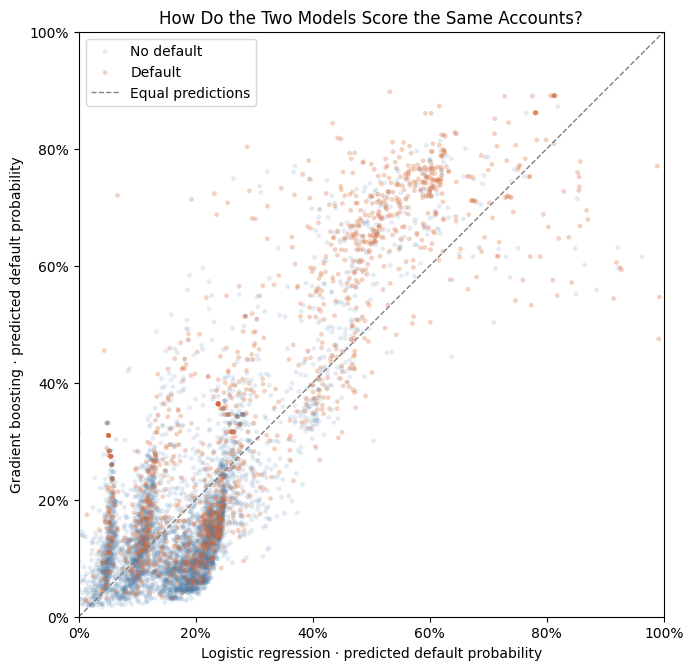

In [33]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

fig, ax = plt.subplots(figsize=(7, 7))

for outcome, label, color, alpha in [
    (0, "No default", "#517EA8", 0.15),
    (1, "Default", "#D66A3A", 0.30),
]:
    group = boosted_results.loc[boosted_results["actual_default"] == outcome]
    ax.scatter(
        group["predicted_probability"],
        group["boosted_probability"],
        s=12,
        alpha=alpha,
        color=color,
        edgecolors="none",
        label=label,
    )

ax.plot([0, 1], [0, 1], "--", color="gray", linewidth=1, label="Equal predictions")
ax.set(
    title="How Do the Two Models Score the Same Accounts?",
    xlabel="Logistic regression · predicted default probability",
    ylabel="Gradient boosting · predicted default probability",
    xlim=(0, 1),
    ylim=(0, 1),
    aspect="equal",
)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend(loc="upper left")

fig.tight_layout()
plt.show()

In [34]:
# Focus on accounts with similar logistic regression scores.
band = boosted_results.loc[
    boosted_results["predicted_probability"].between(0.20, 0.25)
].sort_values("boosted_probability", kind="stable")

group_size = len(band) // 4

if group_size == 0:
    print("Too few accounts in this score band.")
else:
    print(f"Accounts in the 20–25% logistic score band: {len(band):,}\n")

    for label, group in [
        ("Lowest 25% by boosting score", band.head(group_size)),
        ("Highest 25% by boosting score", band.tail(group_size)),
    ]:
        print(
            f"{label}: {len(group):,} accounts | "
            f"avg. logistic score {group['predicted_probability'].mean():.1%} | "
            f"avg. boosting score {group['boosted_probability'].mean():.1%} | "
            f"observed default rate {group['actual_default'].mean():.1%}"
        )

Accounts in the 20–25% logistic score band: 1,492

Lowest 25% by boosting score: 373 accounts | avg. logistic score 21.4% | avg. boosting score 8.1% | observed default rate 7.8%
Highest 25% by boosting score: 373 accounts | avg. logistic score 23.5% | avg. boosting score 24.9% | observed default rate 21.4%


,accounts,avg_logistic_score,avg_boosting_score,observed_default_rate
boosting_quartile,,,,
1,373,21.4%,8.1%,7.8%
2,373,22.4%,12.7%,13.1%
3,373,23.0%,16.0%,16.9%
4,373,23.5%,24.9%,21.4%


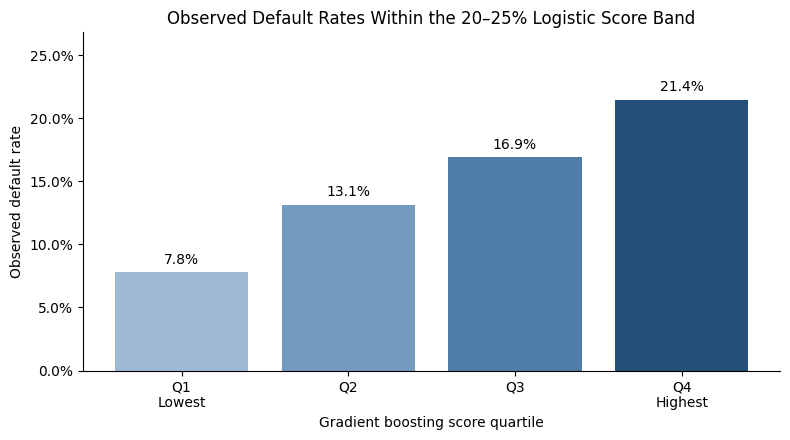

In [35]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

band = boosted_results.loc[
    boosted_results["predicted_probability"].between(0.20, 0.25)
].sort_values("boosted_probability", kind="stable").copy()

# Split the ranked accounts into four equally sized groups.
band["boosting_quartile"] = np.repeat(np.arange(1, 5), len(band) // 4)

summary = band.groupby("boosting_quartile").agg(
    accounts=("actual_default", "size"),
    avg_logistic_score=("predicted_probability", "mean"),
    avg_boosting_score=("boosted_probability", "mean"),
    observed_default_rate=("actual_default", "mean"),
)

display(summary.style.format({
    "avg_logistic_score": "{:.1%}",
    "avg_boosting_score": "{:.1%}",
    "observed_default_rate": "{:.1%}",
}))

fig, ax = plt.subplots(figsize=(8, 4.5))
rates = summary["observed_default_rate"]
bars = ax.bar(
    ["Q1\nLowest", "Q2", "Q3", "Q4\nHighest"],
    rates,
    color=["#9EBAD2", "#749ABD", "#4E7DA7", "#234F78"],
)

ax.bar_label(bars, labels=[f"{rate:.1%}" for rate in rates], padding=4)
ax.set(
    title="Observed Default Rates Within the 20–25% Logistic Score Band",
    xlabel="Gradient boosting score quartile",
    ylabel="Observed default rate",
    ylim=(0, rates.max() * 1.25),
)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

In [36]:
print(
    f"At the same capacity, gradient boosting identified "
    f"{boosted_captured:,} of the {total_defaults:,} accounts that defaulted "
    f"the following month ({boosted_captured / total_defaults:.1%})."
)

At the same capacity, gradient boosting identified 413 of the 1,327 accounts that defaulted the following month (31.1%).


In [37]:
baseline_ids = review_queue.index
boosting_ids = boosted_queue.index

common_ids = baseline_ids.intersection(boosting_ids)
added_ids = boosting_ids.difference(baseline_ids)
removed_ids = baseline_ids.difference(boosting_ids)

queue_changes = pd.DataFrame([
    {
        "Group": label,
        "Accounts": len(ids),
        "Actual defaults": int(results.loc[ids, "actual_default"].sum()),
    }
    for label, ids in [
        ("Selected by both models", common_ids),
        ("Added by gradient boosting", added_ids),
        ("Removed by gradient boosting", removed_ids),
    ]
])

display(queue_changes)

,Group,Accounts,Actual defaults
0,Selected by both models,509,356
1,Added by gradient boosting,91,57
2,Removed by gradient boosting,91,53


In [38]:
# Match payment histories to the row order used in results.
payment_status = X_test[["X6", "X7", "X8", "X9", "X10", "X11"]].copy()
payment_status.index = results.index

history = results[["actual_default"]].copy()
history["recently_late"] = payment_status["X6"].ge(1)
history["late_months"] = payment_status.ge(1).sum(axis=1)

profiles = []

for label, ids in [
    ("Defaults newly captured by boosting", added_ids),
    ("Defaults missed after switching to boosting", removed_ids),
]:
    group = history.loc[ids]
    defaults = group.loc[group["actual_default"].eq(1)]

    profiles.append({
        "Group": label,
        "Accounts": len(defaults),
        "Late in most recent month": defaults["recently_late"].mean(),
        "Average late months out of six": defaults["late_months"].mean(),
    })

display(pd.DataFrame(profiles).style.format({
    "Late in most recent month": "{:.1%}",
    "Average late months out of six": "{:.2f}",
}))

,Group,Accounts,Late in most recent month,Average late months out of six
0,Defaults newly captured by boosting,57,100.0%,2.28
1,Defaults missed after switching to boosting,53,100.0%,4.17


In [39]:
default_history = history.loc[history["actual_default"].eq(1)].copy()

default_history["Logistic regression"] = default_history.index.isin(baseline_ids)
default_history["Gradient boosting"] = default_history.index.isin(boosting_ids)

capture = default_history.groupby("late_months").agg(
    actual_defaults=("actual_default", "size"),
    logistic_captured=("Logistic regression", "sum"),
    boosting_captured=("Gradient boosting", "sum"),
)

capture["Net change"] = capture["boosting_captured"] - capture["logistic_captured"]
capture["Logistic capture rate"] = (
    capture["logistic_captured"] / capture["actual_defaults"]
)
capture["Boosting capture rate"] = (
    capture["boosting_captured"] / capture["actual_defaults"]
)

display(capture.style.format({
    "Logistic capture rate": "{:.1%}",
    "Boosting capture rate": "{:.1%}",
}))

,actual_defaults,logistic_captured,boosting_captured,Net change,Logistic capture rate,Boosting capture rate
late_months,,,,,,
0,504,0,0,0,0.0%,0.0%
1,250,48,73,25,19.2%,29.2%
2,124,40,42,2,32.3%,33.9%
3,116,58,59,1,50.0%,50.9%
4,100,58,49,-9,58.0%,49.0%
5,29,21,18,-3,72.4%,62.1%
6,204,184,172,-12,90.2%,84.3%


In [40]:
capacity_checks = []

for share in [0.05, 0.10, 0.15]:
    n_review = round(len(boosted_results) * share)

    logistic_queue = boosted_results.nlargest(n_review, "predicted_probability")
    boosting_queue = boosted_results.nlargest(n_review, "boosted_probability")

    logistic_count = int(logistic_queue["actual_default"].sum())
    boosting_count = int(boosting_queue["actual_default"].sum())

    capacity_checks.append({
        "Review capacity": f"{share:.0%}",
        "Accounts reviewed": n_review,
        "Logistic defaults captured": logistic_count,
        "Boosting defaults captured": boosting_count,
        "Net change": boosting_count - logistic_count,
    })

display(pd.DataFrame(capacity_checks))

,Review capacity,Accounts reviewed,Logistic defaults captured,Boosting defaults captured,Net change
0,5%,300,215,227,12
1,10%,600,409,413,4
2,15%,900,539,560,21


### Findings and Implications

Gradient boosting flagged more next-month defaults than logistic regression at all three review capacities tested on the same evaluation sample. It captured 12 more defaults when reviewing 5% of accounts, four more at 10%, and 21 more at 15%.

At the 10% review capacity, the net gain of four defaults masked a shift in who made the review list. Gradient boosting captured 28 more defaults among accounts with one to three months of recorded delinquency and 24 fewer among accounts with four to six months. At that same capacity, both models missed all 504 defaults among accounts with no recorded delinquency in the six-month history.

I would test whether these patterns hold in a later cohort before recommending a model change. The results also raise a question about what the models can see before delinquency appears. That distinction leads into Part 2, which examines repayment capacity directly through a hypothetical corporate lending decision.

## Part 2 — Underwriting a Secured Corporate Loan

In Part 1, I used payment history to estimate next-month default risk for
existing credit card accounts. An exploratory analysis found observed default
rates of 7.8% and 21.4% across two groups that the baseline model had scored
within the same 20–25% range.

That finding raised a different question from my lending experience:
what cash flow will the borrower use to repay, and what can the lender
recover if that cash flow falls short?

In this case study, I use public financial statements to assess a hypothetical
secured corporate loan. I test whether operating cash flow can cover debt
service under base and downside scenarios, then estimate potential collateral
recovery separately. The goal is to recommend a loan amount and terms.

### Borrower and Loan Request

In [41]:
# Fastenal FY2025 Form 10-K, USD millions
annual_sales = 8_200.5
year_end_net_receivables = 1_245.3

# Hypothetical downside scenario
additional_collection_days = 10

# First-pass estimate using total sales as a proxy for credit sales
daily_sales = annual_sales / 365
additional_cash_tied_up = daily_sales * additional_collection_days

print(f"FY2025 year-end net receivables: ${year_end_net_receivables:,.1f}M")
print(f"Additional cash tied up under a 10-day delay: ${additional_cash_tied_up:,.1f}M")

FY2025 year-end net receivables: $1,245.3M
Additional cash tied up under a 10-day delay: $224.7M


### Primary Repayment Source — Cash Flow Stress Test

In [42]:
# Fastenal FY2025 Form 10-K, USD millions
operating_cash_flow = 1_295.9
net_capex = 230.6
existing_principal_due = 25.0

# Hypothetical secured loan, USD millions
loan_amount = 250.0
annual_interest_rate = 0.06
loan_term_years = 3

# Assume the first principal payment is made at year-end.
new_principal = loan_amount / loan_term_years
new_interest = loan_amount * annual_interest_rate
payments_to_cover = existing_principal_due + new_principal + new_interest

# Reported operating cash flow already reflects historical cash interest.
# Use it as a starting point and subtract only incremental new-loan interest
# through the payments-to-cover calculation.
base_cash = operating_cash_flow - net_capex
stress_cash = base_cash - additional_cash_tied_up

print(f"First-year payments to cover: ${payments_to_cover:,.1f}M\n")

for scenario, available_cash in [
    ("FY2025 baseline", base_cash),
    ("10-day collection delay", stress_cash),
]:
    print(
        f"{scenario}: "
        f"${available_cash:,.1f}M available | "
        f"{available_cash / payments_to_cover:.2f}x coverage | "
        f"${available_cash - payments_to_cover:,.1f}M remaining"
    )

First-year payments to cover: $123.3M

FY2025 baseline: $1,065.3M available | 8.64x coverage | $942.0M remaining
10-day collection delay: $840.6M available | 6.82x coverage | $717.3M remaining


### Borrower Risk Assessment — Liquidity Stress Test

In [43]:
# Fastenal FY2025 Form 10-K, USD millions
year_end_cash = 276.8
revolver_commitment = 835.0
revolver_drawn = 0.0
outstanding_letters_of_credit = 29.7

# Illustrative timing stress before any new loan proceeds.
# Assume the collection delay and existing principal maturity overlap.
cash_needed = additional_cash_tied_up + existing_principal_due
cash_remaining = year_end_cash - cash_needed

# Availability is conditional on the existing facility terms.
undrawn_revolver = (
    revolver_commitment - revolver_drawn - outstanding_letters_of_credit
)

print(f"Cash needed under timing stress: ${cash_needed:,.1f}M")
print(f"Cash remaining before drawing the revolver: ${cash_remaining:,.1f}M")
print(f"Indicative undrawn revolver capacity: ${undrawn_revolver:,.1f}M")

Cash needed under timing stress: $249.7M
Cash remaining before drawing the revolver: $27.1M
Indicative undrawn revolver capacity: $805.3M


### Facility Recovery Assessment — Receivables Collateral

In [44]:
# Illustrative assumptions, USD millions
# Assume a first-priority lien and no competing senior claims.
collection_costs = 10.0

scenarios = [
    ("Base", year_end_net_receivables, 0.80, 0.85),
    ("10-day delay + weaker collateral",
     year_end_net_receivables + additional_cash_tied_up, 0.45, 0.60),
]

for name, receivables, eligible_share, recovery_rate in scenarios:
    eligible_receivables = receivables * eligible_share
    net_proceeds = max(0, eligible_receivables * recovery_rate - collection_costs)
    principal_recovered = min(loan_amount, net_proceeds)
    break_even_eligible_share = (
        (loan_amount + collection_costs) / (receivables * recovery_rate)
    )

    print(f"{name}")
    print(f"  Receivables balance: ${receivables:,.1f}M")
    print(f"  Net collateral proceeds: ${net_proceeds:,.1f}M")
    print(f"  New loan principal recovered: {principal_recovered / loan_amount:.1%}")
    print(f"  Minimum eligible share for full principal recovery: "
          f"{break_even_eligible_share:.1%}\n")

Base
  Receivables balance: $1,245.3M
  Net collateral proceeds: $836.8M
  New loan principal recovered: 100.0%
  Minimum eligible share for full principal recovery: 24.6%

10-day delay + weaker collateral
  Receivables balance: $1,470.0M
  Net collateral proceeds: $386.9M
  New loan principal recovered: 100.0%
  Minimum eligible share for full principal recovery: 29.5%



### Credit Recommendation

**Decision.** Defer approval of the proposed USD 250M secured term loan. First, assess whether the existing revolver can meet the working-capital need.

**Primary repayment source.** A 10-day collection delay ties up an estimated USD 224.7M and reduces modeled first-year cash coverage from 8.64× to 6.82×. If the delay overlaps with the existing principal maturity, the simplified liquidity stress leaves USD 27.1M of cash before a revolver draw. Annual coverage remains strong, but the timing of cash receipts matters.

**Secondary repayment source.** Under the assumed first-priority lien and downside recovery rates, estimated net collateral proceeds fall from USD 836.8M to USD 386.9M even as receivables increase. Modeled proceeds still cover the proposed USD 250M principal. I would verify receivables aging, customer concentration, and lien priority before relying on that estimate.

**What would change the decision.** As of year-end 2025, the existing revolver showed USD 805.3M of indicative undrawn capacity, subject to its terms. I would request a 13-week cash-flow forecast and confirm how much is available to draw. If the forecast shows a funding gap after accounting for usable revolver capacity and a minimum operating cash buffer, I would size any new facility to that gap.